# 03 · Fig. 1: the two annual lows, when the lowest half hours occur, and photovoltaic (PV) capacity

**Purpose.** Draw Fig. 1 and show the numbers behind it.

**Approximate runtime.** Under 30 seconds.

**Paper section served.** I Introduction.

**Inputs**

- `data/interim/network_30min.parquet` from notebook 01.
- `data/interim/pv_annual.parquet` from notebook 02.

**Paper artifacts**

- `results/figures/fig1.png` (600 dpi) and `fig1.pdf`: Fig. 1, in three panels on one year axis: (a) the annual overnight low and daytime low, (b) a heat map of when each year's lowest 1% of half hours occur, (c) PV capacity.
- `results/tables/fig1_data.csv`: the values plotted in panels (a) and (c).
- `results/tables/fig1_hours.csv`: the share by hour and year plotted in panel (b).

**Supporting checks.** None. The annual maximum and energy by year are in `results/checks/check_annual_summary.csv` (notebook 01). The share of the lowest half hours in each trough window is in `results/checks/check_low_hours.csv` (notebook 04).

**Main process**

1. Set up.
2. Each year's two lows and PV capacity.
3. When the lowest half hours occur.
4. Draw and save Fig. 1.
5. Result.

In the figures a low is labelled "minimum demand": the daytime low reads "daytime minimum demand".

Earlier versions of this figure are in `exploration/01_conference/A2_superseded_figures.ipynb`: one with maximum demand and annual energy, and the heat map as a figure of its own.

## 1. Set up

`set_style` applies the shared figure style: one IEEE column wide, 8 pt serif text, no title inside the figure.

In [1]:
import pandas as pd

from pynmdf import plots, targets
from pynmdf.config import load_config

cfg = load_config()
interim, figures, tables = (cfg["dirs"][key] for key in ("interim", "figures", "tables"))
plots.set_style()

pd.set_option("display.width", 220, "display.float_format", "{:,.1f}".format)
total = pd.read_parquet(interim / "network_30min.parquet")["total_mw"]
capacity = pd.read_parquet(interim / "pv_annual.parquet")["kwp"]

## 2. Each year's two lows and PV capacity

The year's minimum is split in two: the **overnight low** is the lowest valid half hour between 00:00 and 06:00, and the **daytime low** the lowest between 09:00 and 17:00. The year's minimum is the lower of the two. PV capacity is the published network total at 30 June of each year, in MW.

In [2]:
annual = targets.annual_window_lows(total, cfg["targets"]["troughs"]).assign(
    pv_mw=capacity / 1000
)
annual.to_csv(tables / "fig1_data.csv")
annual.T

year,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
overnight_low_mw,"1,368.1","1,432.6","1,474.3","1,495.1","1,473.0","1,429.5","1,387.6","1,428.3","1,393.2","1,419.6","1,434.9"
daytime_low_mw,"1,832.6","1,891.4","1,888.2","1,901.7","1,759.2","1,671.0","1,357.4","1,457.9","1,080.0","1,019.2",880.1
pv_mw,230.0,287.1,345.8,448.7,619.9,780.2,"1,050.4","1,291.3","1,562.6","1,881.7","2,083.7"


## 3. When the lowest half hours occur

Take the lowest 1% of each year's valid half hours (about 170 of them) and count how many start in each clock hour. Times are local clock time.

The table is the data of panel (b): each column sums to 100.

In [3]:
lowest = targets.lowest_intervals(total, cfg["figures"]["low_share"])
hour_shares = targets.low_hour_shares(lowest)
hour_shares.to_csv(tables / "fig1_hours.csv")
hour_shares.round().astype(int).T

hour,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
year,,,,,,,,,,,,,,,,,,,,,
2015,0,0,1,24,48,27,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2016,0,0,0,27,46,23,4,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2017,0,0,1,25,49,22,2,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2018,0,0,0,26,49,21,3,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2019,0,0,0,27,49,22,2,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2020,0,0,1,23,46,28,2,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2021,0,0,0,17,43,19,2,0,0,0,...,3,2,0,0,0,0,0,0,0,0
2022,0,0,4,21,29,16,2,1,0,1,...,5,1,0,0,0,0,0,0,0,0
2023,0,0,0,0,0,0,0,1,2,5,...,12,2,0,0,0,0,0,0,0,0


## 4. Fig. 1

Three panels share the year axis. Panel (a) draws the overnight low and the daytime low as lines, on an axis zoomed to their range. Panel (b) is a heat map of the share of the lowest half hours that start in each clock hour. Panel (c) draws PV capacity as bars from zero. Separate panels are used in place of several y-axes on one panel, so each quantity is read against its own scale and the three line up year by year.

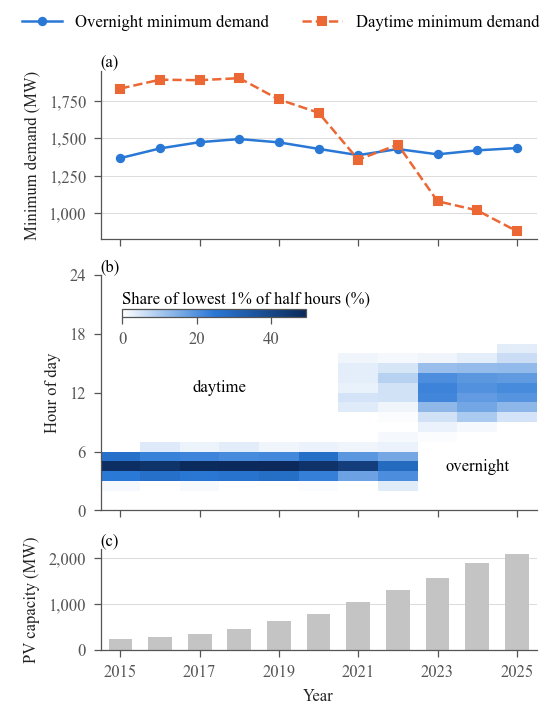

In [4]:
figure = plots.annual_lows_hours_and_pv(annual, hour_shares)
plots.save_figure(figure, figures, "fig1")

## 5. Result

Each series in its first and last year, and the years in which the daytime low sits below the overnight low.

In [5]:
ends = annual.loc[[annual.index[0], annual.index[-1]]].T
ends["change_pct"] = 100 * (ends.iloc[:, 1] / ends.iloc[:, 0] - 1)

daytime_lower = annual.index[annual["daytime_low_mw"] < annual["overnight_low_mw"]]
print("Years in which the daytime low is below the overnight low:", daytime_lower.tolist())
ends

Years in which the daytime low is below the overnight low: [2021, 2023, 2024, 2025]


year,2015,2025,change_pct
overnight_low_mw,"1,368.1","1,434.9",4.9
daytime_low_mw,"1,832.6",880.1,-52.0
pv_mw,230.0,"2,083.7",806.0
